In [1]:
from pathlib import Path
import pandas as pd

processed_dir = Path(r'C:\Users\Afrano\Documents\Quera\my_project\incident-sentiment-analyzer-20261029T081712Z-1-001\incident-sentiment-analyzer-20261029T081712Z-1-001\incident-sentiment-analyzer\notebooks\data\processed')
train_df = pd.read_csv(processed_dir / "train_v2.csv", dtype={"video_id": str})
val_df = pd.read_csv(processed_dir / "val_v2.csv", dtype={"video_id": str})
test_df = pd.read_csv(processed_dir / "test_v2.csv", dtype={"video_id": str})
valid_videos_df = pd.read_csv(processed_dir / "valid_videos_v2.csv", dtype={"video_id": str})

for dataframe in (train_df, val_df, test_df, valid_videos_df):
    dataframe["video_id"] = dataframe["video_id"].str.zfill(5)

print(f"Loaded {len(train_df)} train, {len(val_df)} validation, {len(test_df)} test, and {len(valid_videos_df)} manifest rows.")

Loaded 105 train, 22 validation, 23 test, and 150 manifest rows.


In [2]:
train_ids = set(train_df["video_id"])
val_ids = set(val_df["video_id"])
test_ids = set(test_df["video_id"])

overlap_train_val = train_ids & val_ids
overlap_train_test = train_ids & test_ids
overlap_val_test = val_ids & test_ids

assert not overlap_train_val, f"Train/validation overlap: {sorted(overlap_train_val)}"
assert not overlap_train_test, f"Train/test overlap: {sorted(overlap_train_test)}"
assert not overlap_val_test, f"Validation/test overlap: {sorted(overlap_val_test)}"
print("Split overlap sanity check passed: video IDs are disjoint across all splits.")

Split overlap sanity check passed: video IDs are disjoint across all splits.


In [3]:
expected_split_columns = ["video_id", "label", "class_name", "relative_path"]
split_frames = {"train": train_df, "val": val_df, "test": test_df}

for split_name, dataframe in split_frames.items():
    assert list(dataframe.columns) == expected_split_columns, f"Unexpected {split_name} schema: {list(dataframe.columns)}"
    assert not dataframe.isna().any().any(), f"Null values found in {split_name}"
    assert dataframe["video_id"].str.fullmatch(r"\d{5}").all(), f"Invalid five-digit IDs in {split_name}"
    assert not dataframe["video_id"].duplicated().any(), f"Duplicate video IDs in {split_name}"
    assert set(dataframe["label"].unique()) == {0, 1}, f"Labels in {split_name} must be binary 0/1"
    assert dataframe["class_name"].nunique() == 2, f"Expected two class names in {split_name}"

all_split_rows = pd.concat([dataframe.assign(split=split_name) for split_name, dataframe in split_frames.items()], ignore_index=True)
label_to_class = all_split_rows.groupby("label")["class_name"].nunique()
class_to_label = all_split_rows.groupby("class_name")["label"].nunique()
assert (label_to_class == 1).all() and (class_to_label == 1).all(), "Labels and class names are not consistently concordant"
concordance = all_split_rows[["label", "class_name"]].drop_duplicates()
for split_name, dataframe in split_frames.items():
    split_concordance = dataframe[["label", "class_name"]].drop_duplicates()
    assert set(map(tuple, split_concordance.to_numpy())) == set(map(tuple, concordance.to_numpy())), f"Label/class concordance differs in {split_name}"

print("CSV schemas, nulls, five-digit IDs, binary labels, and per-split label/class concordance validated.")

CSV schemas, nulls, five-digit IDs, binary labels, and per-split label/class concordance validated.


In [4]:
required_manifest_columns = ["video_id", "split", "label", "path"]
assert list(valid_videos_df.columns) == required_manifest_columns, f"Unexpected manifest schema: {list(valid_videos_df.columns)}"
assert not valid_videos_df.isna().any().any(), "Null values found in valid_videos_v2.csv"
assert set(valid_videos_df["split"].unique()) == {"train", "val", "test"}, "Manifest split names must be train, val, and test"
assert not valid_videos_df["video_id"].duplicated().any(), "Manifest video IDs must be unique"
assert valid_videos_df["video_id"].str.fullmatch(r"\d{5}").all(), "Manifest IDs must be five digits"
assert set(valid_videos_df["label"].unique()) == {0, 1}, "Manifest labels must be binary 0/1"
print(f"Manifest schema and fields validated: {len(valid_videos_df)} unique video IDs.")

Manifest schema and fields validated: 150 unique video IDs.


In [5]:
split_summary = all_split_rows.groupby("split").agg(video_count=("video_id", "nunique"), row_count=("video_id", "size")).sort_index()
label_distribution = all_split_rows.groupby(["split", "label"]).size().unstack(fill_value=0).sort_index()
print("Video counts by split:")
print(split_summary)
print("\nLabel distribution by split:")
print(label_distribution)

Video counts by split:
       video_count  row_count
split                        
test            23         23
train          105        105
val             22         22

Label distribution by split:
label   0   1
split        
test    7  16
train  52  53
val     8  14


In [6]:
for split_name, dataframe in split_frames.items():
    unique_ids = sorted(dataframe["video_id"].unique())
    print(f"{split_name} ({len(unique_ids)} unique video IDs):")
    print(unique_ids)

train (105 unique video IDs):
['00011', '00012', '00020', '00033', '00050', '00052', '00073', '00088', '00101', '00115', '00126', '00139', '00146', '00150', '00161', '00165', '00178', '00182', '00185', '00186', '00191', '00193', '00198', '00204', '00219', '00220', '00221', '00229', '00243', '00246', '00248', '00257', '00261', '00278', '00281', '00293', '00304', '00306', '00314', '00315', '00323', '00346', '00347', '00350', '00352', '00359', '00368', '00377', '00379', '00384', '00396', '00404', '00412', '00438', '00442', '00446', '00465', '00470', '00489', '00492', '00499', '00507', '00508', '00509', '00513', '00514', '00518', '00524', '00525', '00536', '01047', '01055', '01057', '01064', '01068', '01082', '01086', '01087', '01091', '01104', '01105', '01106', '01107', '01110', '01123', '01124', '01158', '01160', '01166', '01174', '01188', '01198', '01199', '01200', '01203', '01233', '01241', '01243', '01251', '01304', '01314', '01325', '01337', '01345', '01347']
val (22 unique video IDs

In [7]:
manifest_source = all_split_rows[["video_id", "split", "label", "relative_path"]].rename(columns={"relative_path": "path"})
manifest_expected = manifest_source.sort_values(["video_id", "split"]).reset_index(drop=True)
manifest_actual = valid_videos_df[["video_id", "split", "label", "path"]].sort_values(["video_id", "split"]).reset_index(drop=True)

assert len(manifest_expected) == 150, f"Expected exactly 150 split video rows, found {len(manifest_expected)}"
assert len(manifest_actual) == 150, f"Expected exactly 150 manifest rows, found {len(manifest_actual)}"
pd.testing.assert_frame_equal(manifest_expected, manifest_actual, check_dtype=False, check_like=False)
print(f"Manifest reconciliation passed: all {len(manifest_actual)} videos match on video_id, split, label, and path.")

Manifest reconciliation passed: all 150 videos match on video_id, split, label, and path.


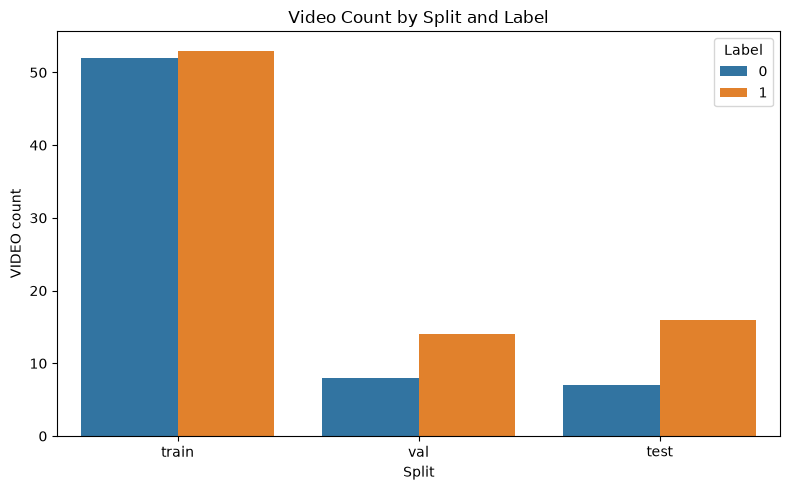

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = all_split_rows.copy()
plot_data["split"] = pd.Categorical(plot_data["split"], categories=["train", "val", "test"], ordered=True)
plt.figure(figsize=(8, 5))
sns.countplot(data=plot_data, x="split", hue="label", order=["train", "val", "test"])
plt.xlabel("Split")
plt.ylabel("VIDEO count")
plt.title("Video Count by Split and Label")
plt.legend(title="Label")
plt.tight_layout()
plt.show()

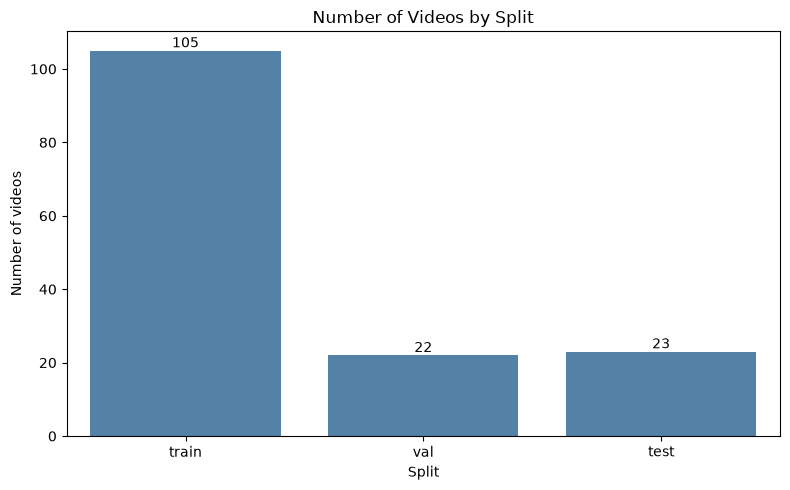

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

video_counts = all_split_rows.groupby("split")["video_id"].nunique().reindex(["train", "val", "test"])
plt.figure(figsize=(8, 5))
sns.barplot(x=video_counts.index, y=video_counts.values, color="steelblue")
plt.xlabel("Split")
plt.ylabel("Number of videos")
plt.title("Number of Videos by Split")
for position, count in enumerate(video_counts.values):
    plt.text(position, count, str(count), ha="center", va="bottom")
plt.tight_layout()
plt.show()

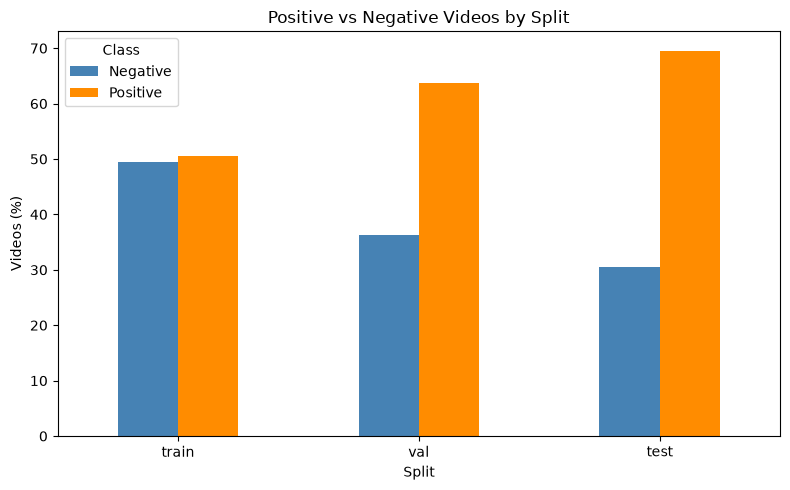

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

class_order = sorted(all_split_rows["class_name"].unique())
percentage_distribution = pd.crosstab(all_split_rows["split"], all_split_rows["class_name"], normalize="index").mul(100).reindex(index=["train", "val", "test"], columns=class_order)
percentage_distribution.columns = [class_name.capitalize() for class_name in percentage_distribution.columns]
percentage_distribution.plot(kind="bar", figsize=(8, 5), color=["steelblue", "darkorange"])
plt.xlabel("Split")
plt.ylabel("Videos (%)")
plt.title("Positive vs Negative Videos by Split")
plt.legend(title="Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
from IPython.display import display

train_metadata_sample = train_df.sample(n=9, random_state=42).sort_values("video_id").reset_index(drop=True)
display(train_metadata_sample[["video_id", "label", "class_name", "relative_path"]])

,video_id,label,class_name,relative_path
0,00012,1,positive,train-20261101T193155Z-1-001/train/positive/00...
1,00178,1,positive,train-20261101T193155Z-1-001/train/positive/00...
2,00182,1,positive,train-20261101T193155Z-1-001/train/positive/00...
3,00278,0,negative,train-20261101T193155Z-1-001/train/negative/00...
4,00489,1,positive,train-20261101T193155Z-1-001/train/positive/00...
5,00536,1,positive,train-20261101T193155Z-1-001/train/positive/00...
6,01110,0,negative,train-20261101T193155Z-1-001/train/negative/01...
7,01251,0,negative,train-20261101T193155Z-1-001/train/negative/01...
8,01314,0,negative,train-20261101T193155Z-1-001/train/negative/01...


In [12]:
expected_split_columns = ["video_id", "label", "class_name", "relative_path"]
for split_name, dataframe in split_frames.items():
    assert list(dataframe.columns) == expected_split_columns
    assert not dataframe.isna().any().any()
    assert dataframe["video_id"].str.fullmatch(r"\d{5}").all()
    assert set(dataframe["label"].unique()) == {0, 1}
    assert not dataframe["video_id"].duplicated().any()
    assert dataframe.groupby("label")["class_name"].nunique().eq(1).all()
    assert dataframe.groupby("class_name")["label"].nunique().eq(1).all()

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)
assert len(all_split_rows) == 150
assert len(valid_videos_df) == 150
assert not valid_videos_df["video_id"].duplicated().any()
assert set(valid_videos_df["split"].unique()) == {"train", "val", "test"}
assert set(map(tuple, manifest_expected.to_numpy())) == set(map(tuple, manifest_actual.to_numpy()))
assert len(manifest_expected) == len(manifest_actual) == 150
print("All global integrity checks passed: schemas, disjoint splits, labels/classes, completeness, and exact manifest correspondence.")

All global integrity checks passed: schemas, disjoint splits, labels/classes, completeness, and exact manifest correspondence.
